<a href="https://colab.research.google.com/github/donggeunlee77/chest-CT-DL/blob/main/loadingDICOM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip -q install kaggle

import os, json
from google.colab import files

files.upload()

Saving kaggle.json to kaggle.json


{'kaggle.json': b'{"username":"dongdol77","key":"2ef624f0153defff556c764347959894"}'}

In [ ]:
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

In [ ]:
!kaggle competitions list -s osic

ref                                                                      deadline             category       reward  teamCount  userHasEntered  
-----------------------------------------------------------------------  -------------------  ---------  ----------  ---------  --------------  
https://www.kaggle.com/competitions/osic-pulmonary-fibrosis-progression  2020-10-06 23:59:00  Featured   55,000 Usd       2097            True  
https://www.kaggle.com/competitions/deteccin-de-posiciones-de-yoga       2021-07-11 04:00:00  Community       Kudos         22           False  
https://www.kaggle.com/competitions/tkaicompetition                      2022-10-16 23:59:00  Community       Kudos          0           False  


In [ ]:
!kaggle competitions download -c osic-pulmonary-fibrosis-progression

100% 13.3G/13.3G [11:04<00:00, 21.6MB/s]



In [ ]:
!df -h /content

Filesystem      Size  Used Avail Use% Mounted on
overlay         113G   61G   53G  54% /


In [ ]:
!ls -lh /content/

total 14G
-rw-r--r-- 1 root root   65 Aug 25 11:59 'kaggle (1).json'
-rw-r--r-- 1 root root   65 Aug 25 12:00  kaggle.json
-rw-r--r-- 1 root root  14G Jul 10  2020  osic-pulmonary-fibrosis-progression.zip
drwxr-xr-x 1 root root 4.0K Aug 20 13:35  sample_data


In [ ]:
!du -h /content/osic-pulmonary-fibrosis-progression.zip

14G	/content/osic-pulmonary-fibrosis-progression.zip


In [ ]:
!mkdir -p /content/osic
!unzip -q /content/osic-pulmonary-fibrosis-progression.zip -d /content/osic

In [ ]:
import numpy as np
import pandas as pd
import os
import json
from pathlib import Path
from glob import glob
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.utils import load_img, img_to_array
from keras import models, regularizers, layers, optimizers, losses, metrics
from keras.models import Sequential
from keras.layers import Dense
from keras.utils import to_categorical
from keras.preprocessing.image import img_to_array
from keras.preprocessing import image

##

In [ ]:
data_path = Path('/content/osic/')
train_path = data_path / 'train'
test_path = data_path / 'test'
print(train_path, test_path)

/content/osic/train /content/osic/test


In [ ]:
!ls /content/osic/

sample_submission.csv  test  test.csv  train  train.csv


In [ ]:
!pip install pydicom
import pydicom
from pydicom.data import get_testdata_files
print(__doc__)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 84.9 MB/s eta 0:00:00
Automatically created module for IPython interactive environment


In [ ]:
PathDicom = '/content/osic/'
lstFilesDCM = []
for dirName, subdirList, fileList in os.walk(PathDicom):
  for filename in fileList:
    if '.dcm' in filename.lower():
      lstFilesDCM.append(os.path.join(dirName,filename))

In [ ]:
print(lstFilesDCM[0])

/content/osic/test/ID00423637202312137826377/75.dcm


In [ ]:
RefDs = pydicom.dcmread(lstFilesDCM[0])
RefDs

Dataset.file_meta -------------------------------
(0002,0000) File Meta Information Group Length  UL: 200
(0002,0001) File Meta Information Version       OB: b'\x00\x01'
(0002,0002) Media Storage SOP Class UID         UI: CT Image Storage
(0002,0003) Media Storage SOP Instance UID      UI: 2.25.104946319174047912859131821442369817842
(0002,0010) Transfer Syntax UID                 UI: Explicit VR Little Endian
(0002,0012) Implementation Class UID            UI: 1.2.276.0.7230010.3.0.3.6.1
(0002,0013) Implementation Version Name         SH: 'OSIRIX_361'
(0002,0016) Source Application Entity Title     AE: 'ANONYMOUS'
-------------------------------------------------
(0008,0005) Specific Character Set              CS: 'ISO_IR 100'
(0008,0008) Image Type                          CS: ['ORIGINAL', 'PRIMARY', 'AXIAL', 'HELIX']
(0008,0018) SOP Instance UID                    UI: 2.25.104946319174047912859131821442369817842
(0008,0060) Modality                            CS: 'CT'
(0008,0070) Ma

In [ ]:
ConstPixelDims = (int(RefDs.Rows), int(RefDs.Columns), len(lstFilesDCM))
print(ConstPixelDims)

(512, 512, 34287)


In [ ]:
pat_name = RefDs.PatientName
display_name = pat_name.family_name + ", " + pat_name.given_name
print("Patient's name................:", display_name)
print("Patient id....................:", RefDs.PatientID)
print("Modality......................:", RefDs.Modality)
print("BodyPartExamined..............:", RefDs.BodyPartExamined)
print("Image Position    (Patient)...:", RefDs.ImagePositionPatient)
print("Image Orientation (Patient)...:", RefDs.ImageOrientationPatient)

Patient's name................: ID00423637202312137826377, 
Patient id....................: ID00423637202312137826377
Modality......................: CT
BodyPartExamined..............: Chest
Image Position    (Patient)...: [-188.5, -56.5, 1011.30005]
Image Orientation (Patient)...: [1, 0, 0, 0, 1, 0]


In [ ]:
if 'PixelData' in RefDs:
  rows = int(RefDs.Rows)
  cols = int(RefDs.Columns)
  print("Image size...: {rows:d} x {cols:d}, {size:d} bytes".format(rows=rows, cols=cols, size=len(RefDs.PixelData)))
  if "PixelSpacing" in RefDs:
    print("Pixel spacing...:", RefDs.PixelSpacing)

print("Slice location...:", RefDs.get('SliceLocation', "(missing)"))

Image size...: 512 x 512, 524288 bytes
Pixel spacing...: [0.693359375, 0.693359375]
Slice location...: -1011.30


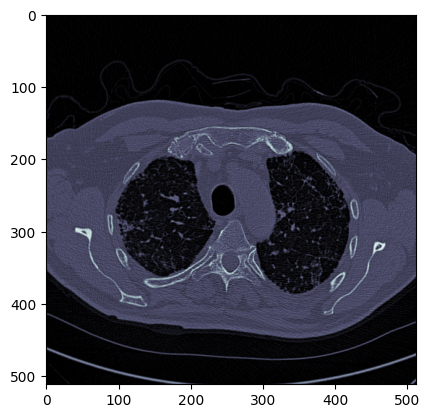

In [ ]:
plt.imshow(RefDs.pixel_array, cmap=plt.cm.bone)
plt.show()

In [ ]:
data = pd.read_csv(data_path / 'test.csv')
data

,Patient,Weeks,FVC,Percent,Age,Sex,SmokingStatus
0,ID00419637202311204720264,6,3020,70.186855,73,Male,Ex-smoker
1,ID00421637202311550012437,15,2739,82.045291,68,Male,Ex-smoker
2,ID00422637202311677017371,6,1930,76.672493,73,Male,Ex-smoker
3,ID00423637202312137826377,17,3294,79.258903,72,Male,Ex-smoker
4,ID00426637202313170790466,0,2925,71.824968,73,Male,Never smoked


In [ ]:
data.loc[data['Patient'] == 'ID00422637202311677017371']

In [ ]:
dim = 25
size = 6
data2Dlist = [[0 for x in range(size)] for y in range(dim)]

In [ ]:
data2Dlist

[[0, 0, 0, 0, 0, 0],
 [0, 0, 0, 0, 0, 0],
 [0, 0, 0, 0, 0, 0],
 [0, 0, 0, 0, 0, 0],
 [0, 0, 0, 0, 0, 0],
 [0, 0, 0, 0, 0, 0],
 [0, 0, 0, 0, 0, 0],
 [0, 0, 0, 0, 0, 0],
 [0, 0, 0, 0, 0, 0],
 [0, 0, 0, 0, 0, 0],
 [0, 0, 0, 0, 0, 0],
 [0, 0, 0, 0, 0, 0],
 [0, 0, 0, 0, 0, 0],
 [0, 0, 0, 0, 0, 0],
 [0, 0, 0, 0, 0, 0],
 [0, 0, 0, 0, 0, 0],
 [0, 0, 0, 0, 0, 0],
 [0, 0, 0, 0, 0, 0],
 [0, 0, 0, 0, 0, 0],
 [0, 0, 0, 0, 0, 0],
 [0, 0, 0, 0, 0, 0],
 [0, 0, 0, 0, 0, 0],
 [0, 0, 0, 0, 0, 0],
 [0, 0, 0, 0, 0, 0],
 [0, 0, 0, 0, 0, 0]]

In [ ]:
for i in range(0,dim):
  print(i, lstFilesDCM[i])
  data2Dlist[i][0] = pydicom.dcmread(lstFilesDCM[i]).PatientID
  data2Dlist[i][1] = pydicom.dcmread(lstFilesDCM[i]).Modality
  data2Dlist[i][2] = pydicom.dcmread(lstFilesDCM[i]).BodyPartExamined
  data2Dlist[i][3] = pydicom.dcmread(lstFilesDCM[i]).InstanceNumber
  data2Dlist[i][4] = '73'
  data2Dlist[i][5] = 'male'
data2Dlist

0 /content/osic/test/ID00423637202312137826377/75.dcm
1 /content/osic/test/ID00423637202312137826377/28.dcm
2 /content/osic/test/ID00423637202312137826377/219.dcm
3 /content/osic/test/ID00423637202312137826377/285.dcm
4 /content/osic/test/ID00423637202312137826377/137.dcm
5 /content/osic/test/ID00423637202312137826377/94.dcm
6 /content/osic/test/ID00423637202312137826377/207.dcm
7 /content/osic/test/ID00423637202312137826377/236.dcm
8 /content/osic/test/ID00423637202312137826377/81.dcm
9 /content/osic/test/ID00423637202312137826377/62.dcm
10 /content/osic/test/ID00423637202312137826377/145.dcm
11 /content/osic/test/ID00423637202312137826377/234.dcm
12 /content/osic/test/ID00423637202312137826377/105.dcm
13 /content/osic/test/ID00423637202312137826377/64.dcm
14 /content/osic/test/ID00423637202312137826377/161.dcm
15 /content/osic/test/ID00423637202312137826377/195.dcm
16 /content/osic/test/ID00423637202312137826377/179.dcm
17 /content/osic/test/ID00423637202312137826377/277.dcm
18 /cont

[['ID00423637202312137826377', 'CT', 'Chest', '75', '73', 'male'],
 ['ID00423637202312137826377', 'CT', 'Chest', '28', '73', 'male'],
 ['ID00423637202312137826377', 'CT', 'Chest', '219', '73', 'male'],
 ['ID00423637202312137826377', 'CT', 'Chest', '285', '73', 'male'],
 ['ID00423637202312137826377', 'CT', 'Chest', '137', '73', 'male'],
 ['ID00423637202312137826377', 'CT', 'Chest', '94', '73', 'male'],
 ['ID00423637202312137826377', 'CT', 'Chest', '207', '73', 'male'],
 ['ID00423637202312137826377', 'CT', 'Chest', '236', '73', 'male'],
 ['ID00423637202312137826377', 'CT', 'Chest', '81', '73', 'male'],
 ['ID00423637202312137826377', 'CT', 'Chest', '62', '73', 'male'],
 ['ID00423637202312137826377', 'CT', 'Chest', '145', '73', 'male'],
 ['ID00423637202312137826377', 'CT', 'Chest', '234', '73', 'male'],
 ['ID00423637202312137826377', 'CT', 'Chest', '105', '73', 'male'],
 ['ID00423637202312137826377', 'CT', 'Chest', '64', '73', 'male'],
 ['ID00423637202312137826377', 'CT', 'Chest', '161', '

In [ ]:
df = pd.DataFrame(data2Dlist, columns=['ID','Modality','BPE','Slice','Age','Sex'])
df

,ID,Modality,BPE,Slice,Age,Sex
0,ID00423637202312137826377,CT,Chest,75,73,male
1,ID00423637202312137826377,CT,Chest,28,73,male
2,ID00423637202312137826377,CT,Chest,219,73,male
3,ID00423637202312137826377,CT,Chest,285,73,male
4,ID00423637202312137826377,CT,Chest,137,73,male
5,ID00423637202312137826377,CT,Chest,94,73,male
6,ID00423637202312137826377,CT,Chest,207,73,male
7,ID00423637202312137826377,CT,Chest,236,73,male
8,ID00423637202312137826377,CT,Chest,81,73,male
9,ID00423637202312137826377,CT,Chest,62,73,male


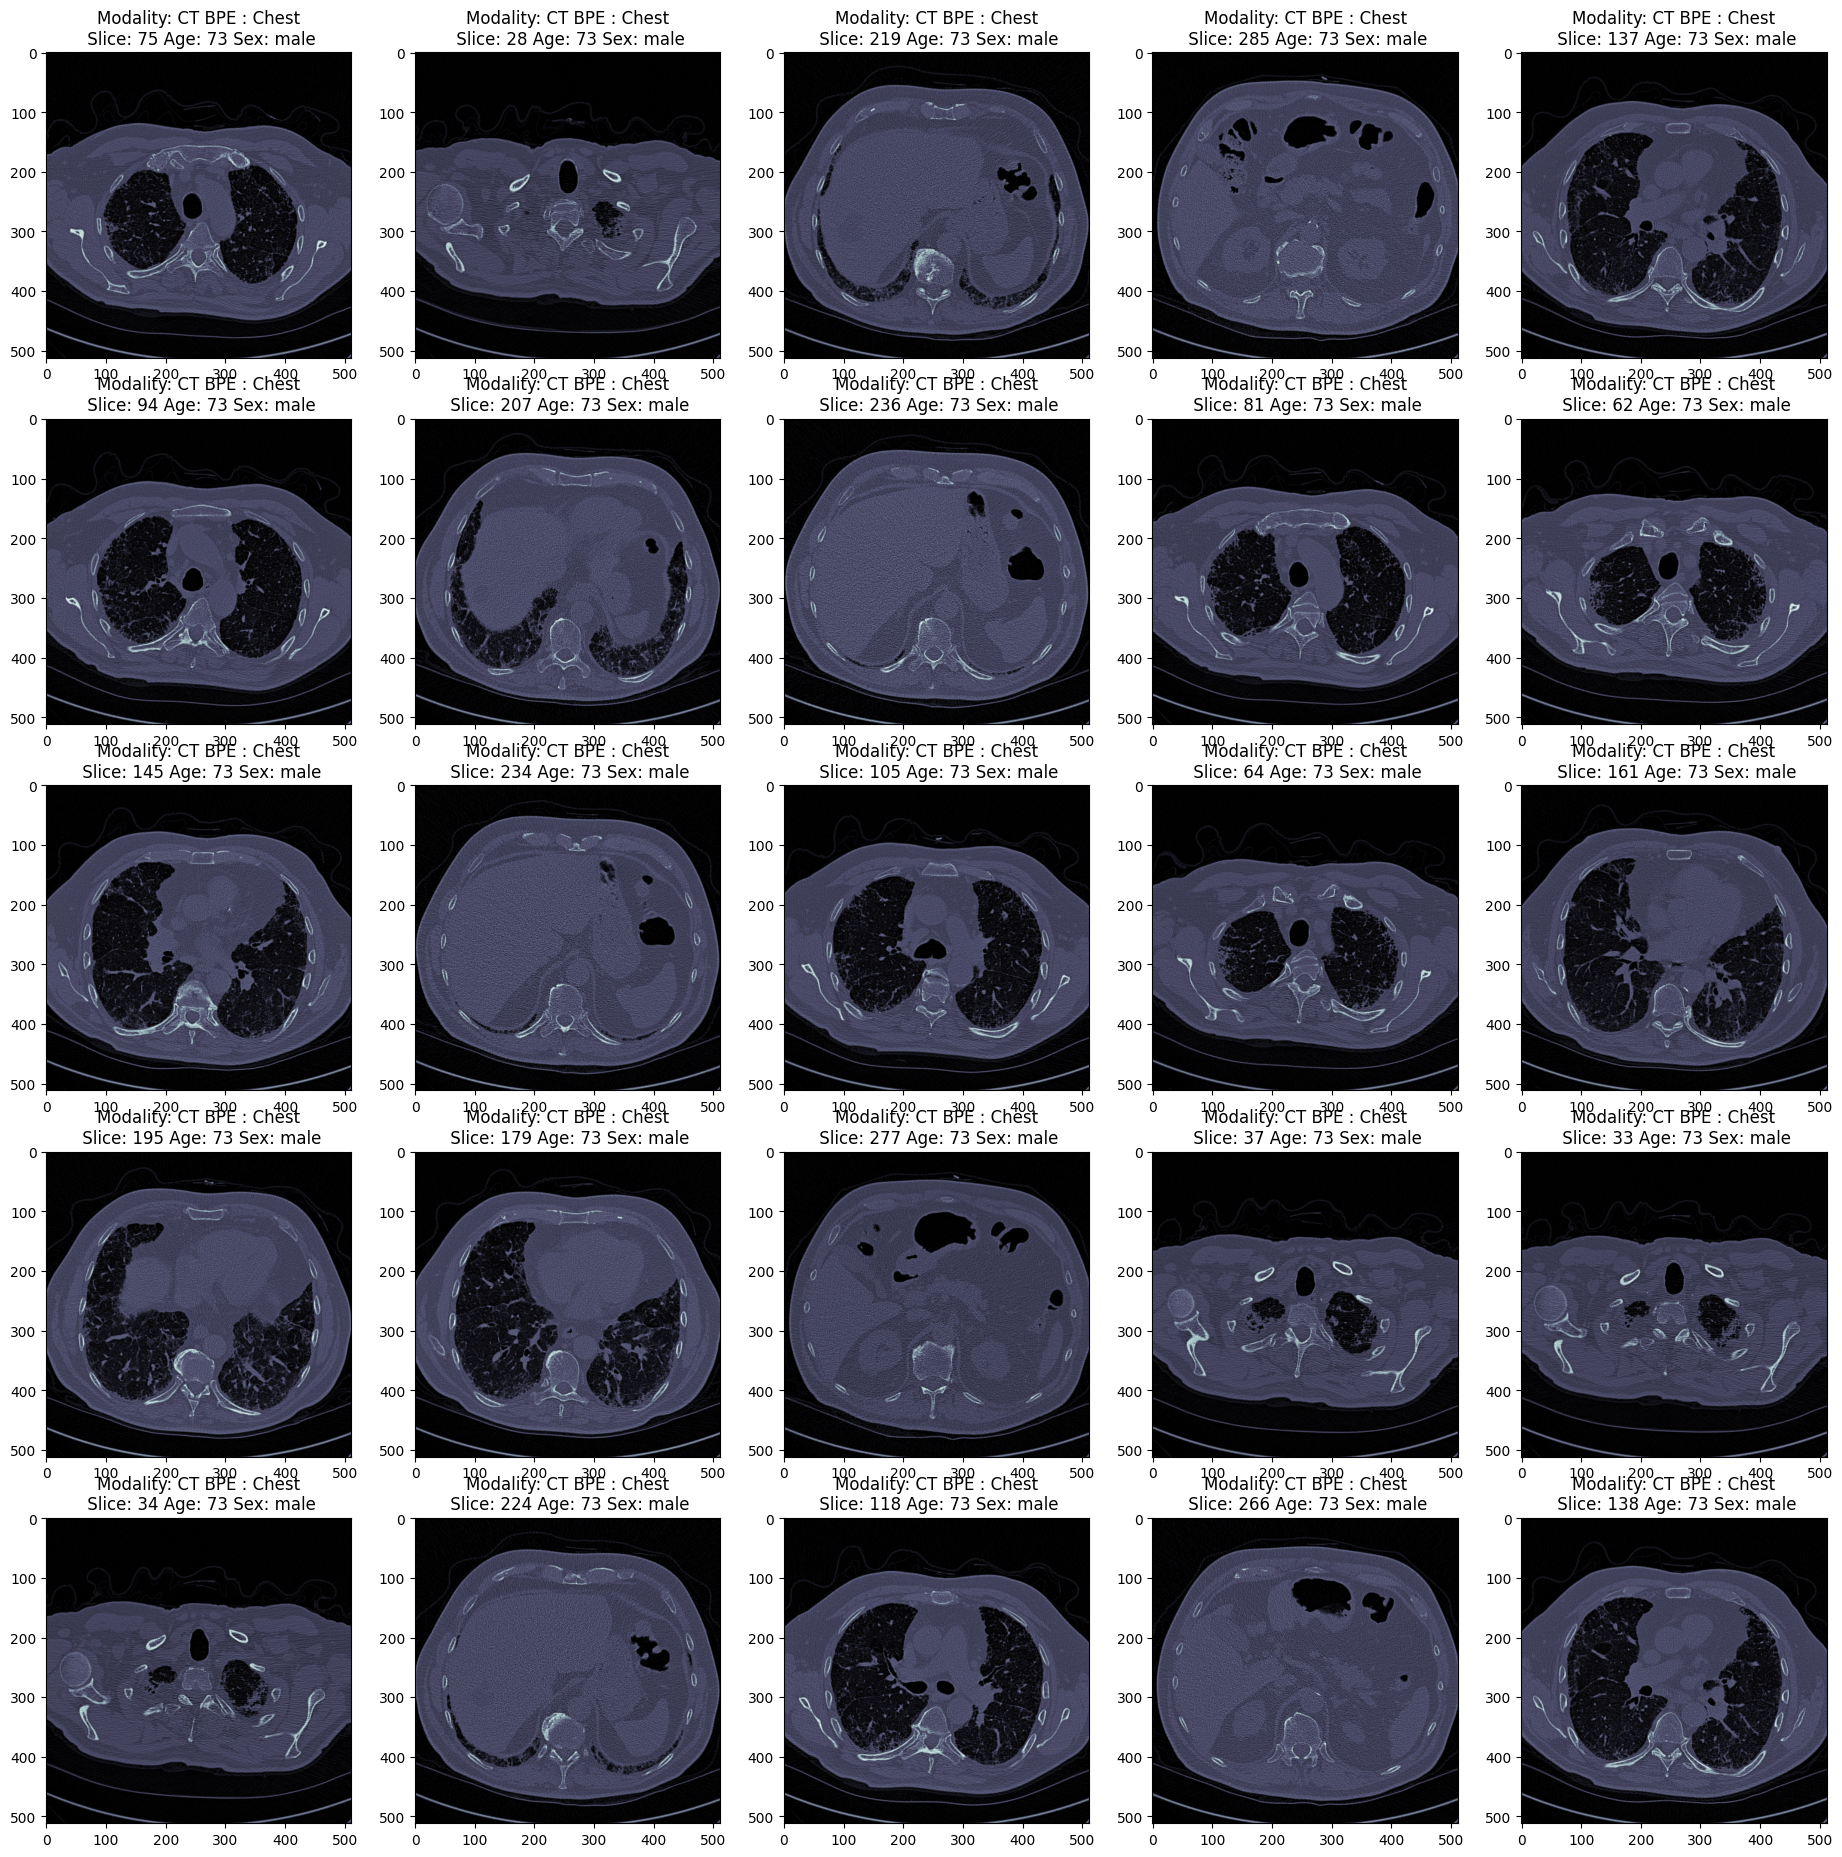

In [ ]:
fig, axs = plt.subplots(5,5, figsize = (23,23))

for i in range(0,25):
  RefDs = pydicom.dcmread(lstFilesDCM[i])
  axs[i//5, i%5].imshow(RefDs.pixel_array, cmap=plt.cm.bone)
  axs[i//5, i%5].set_title('Modality: {} BPE : {}\n Slice: {} Age: {} Sex: {}'. format(df.Modality[i], df.BPE[i], df.Slice[i], df.Age[i], df.Sex[i]))

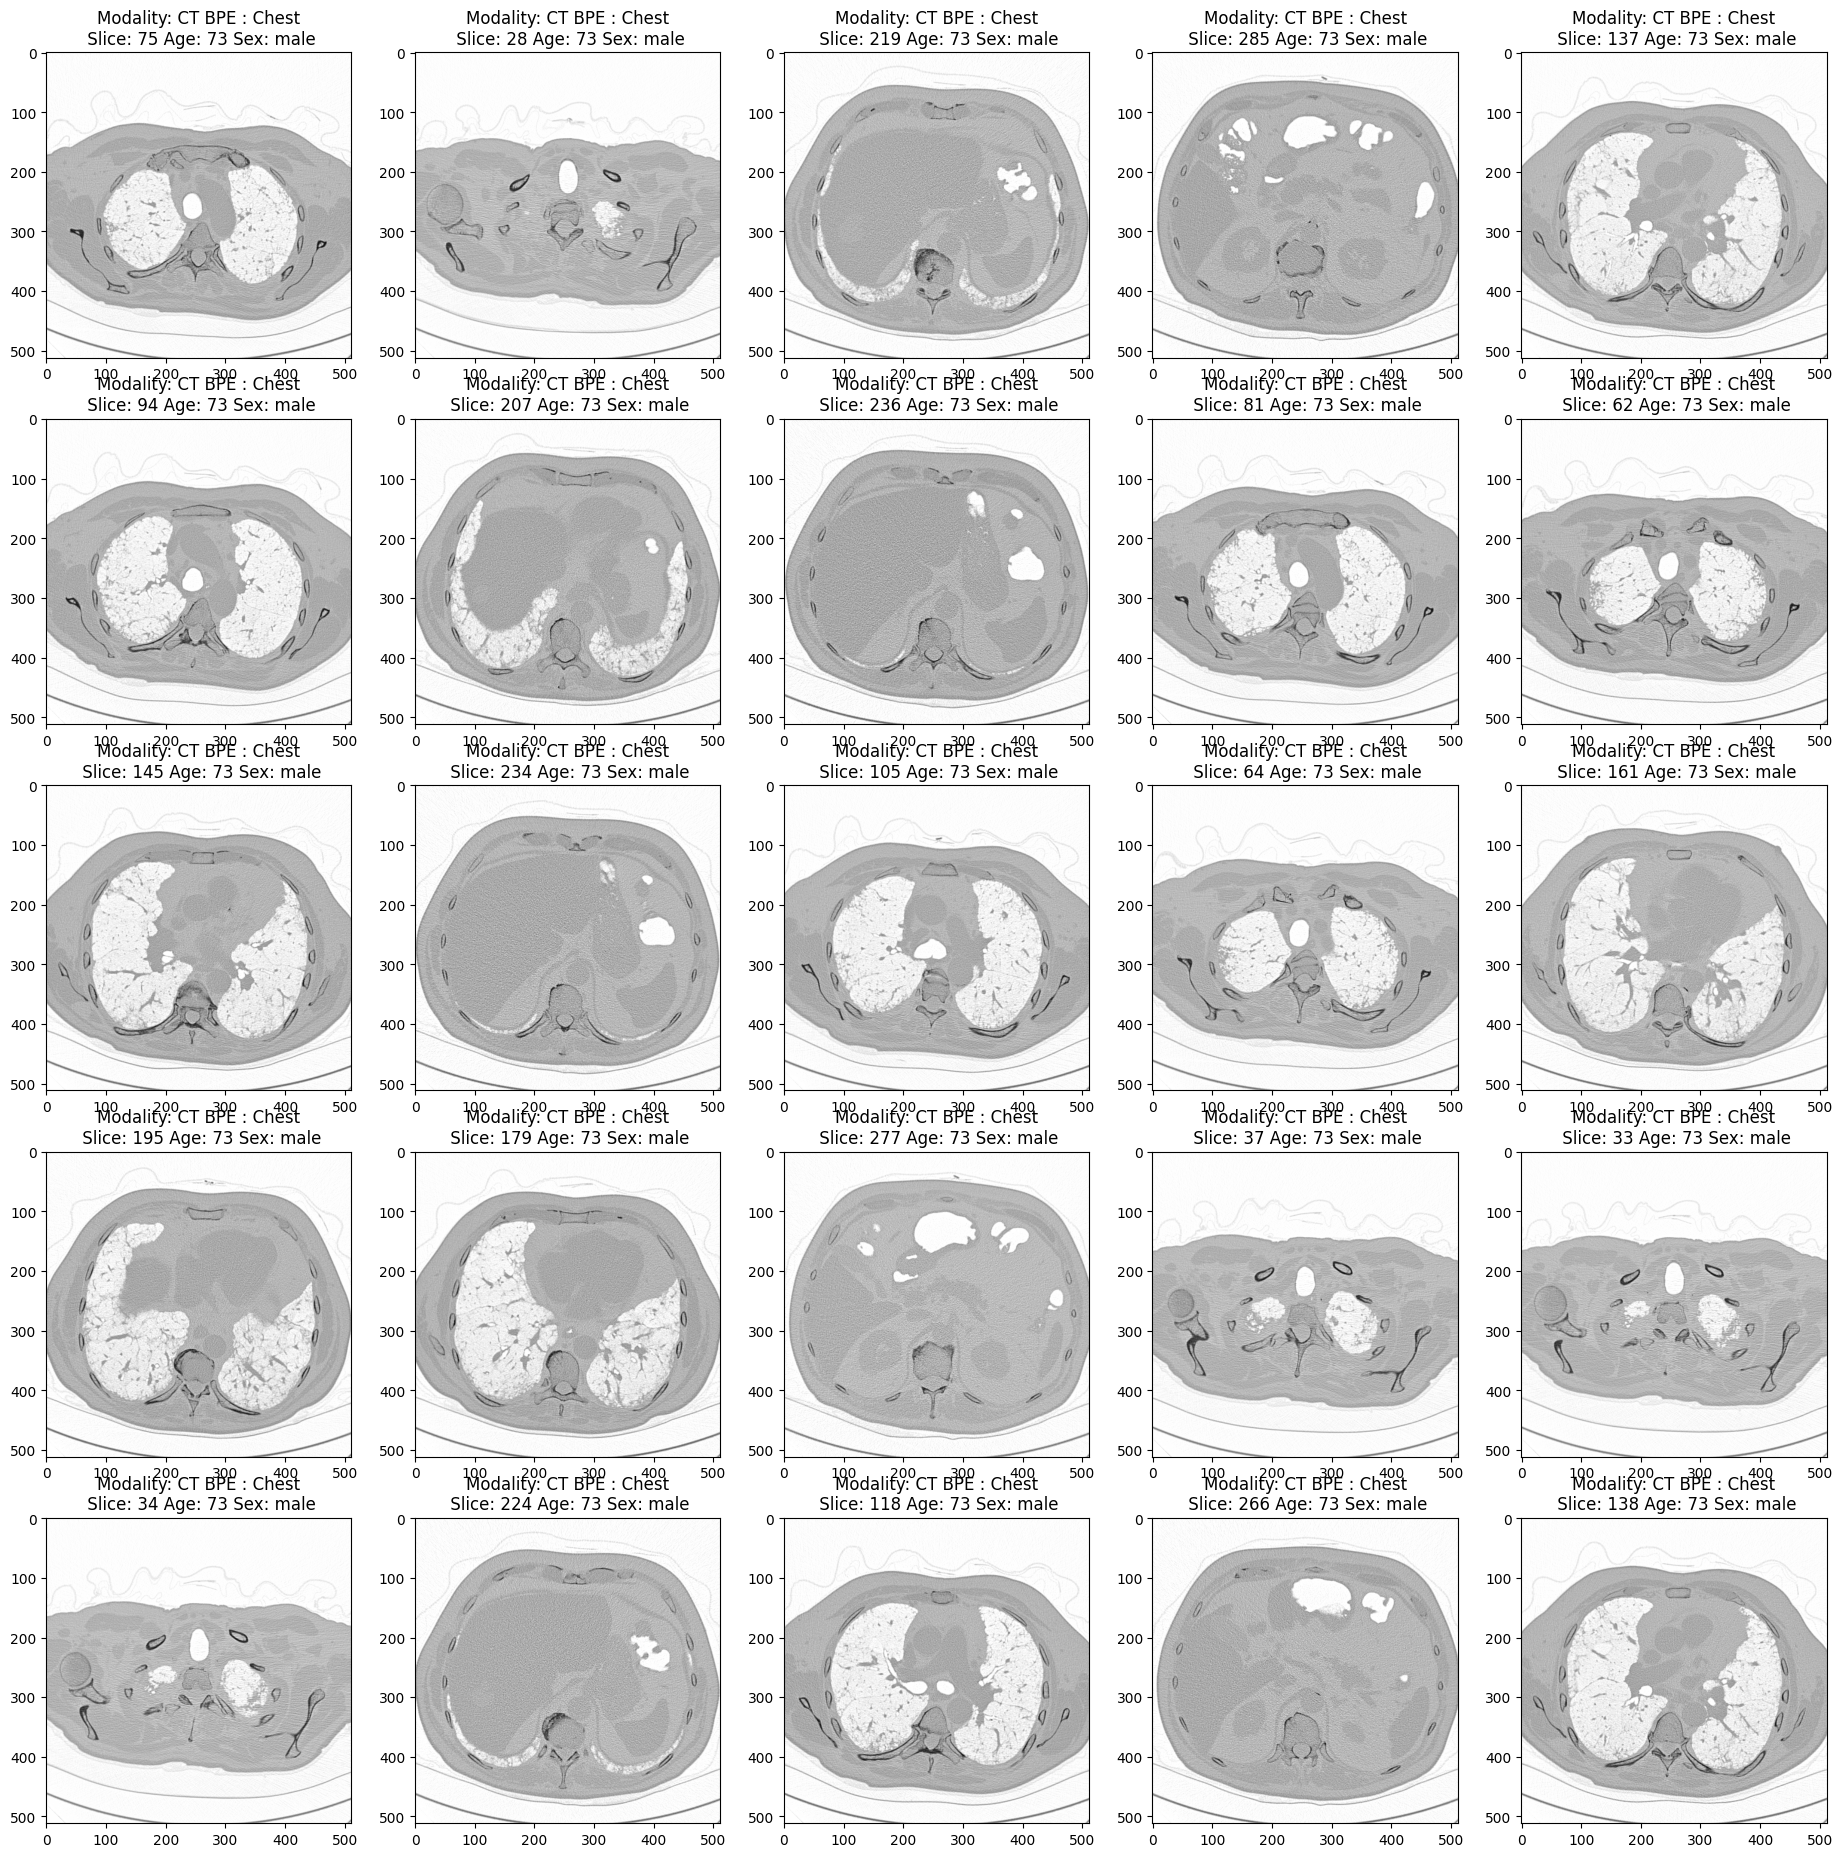

In [ ]:
fig, axs = plt.subplots(5,5, figsize = (23,23))

for i in range(0,25):
  RefDs = pydicom.dcmread(lstFilesDCM[i])
  axs[i//5, i%5].imshow(RefDs.pixel_array, cmap='binary')
  axs[i//5, i%5].set_title('Modality: {} BPE : {}\n Slice: {} Age: {} Sex: {}'. format(df.Modality[i], df.BPE[i], df.Slice[i], df.Age[i], df.Sex[i]))

In [ ]:
train = pd.read_csv(data_path / 'train.csv')
test = pd.read_csv(data_path / 'test.csv')
train.shape, test.shape

((1549, 7), (5, 7))

In [ ]:
train

,Patient,Weeks,FVC,Percent,Age,Sex,SmokingStatus
0,ID00007637202177411956430,-4,2315,58.253649,79,Male,Ex-smoker
1,ID00007637202177411956430,5,2214,55.712129,79,Male,Ex-smoker
2,ID00007637202177411956430,7,2061,51.862104,79,Male,Ex-smoker
3,ID00007637202177411956430,9,2144,53.950679,79,Male,Ex-smoker
4,ID00007637202177411956430,11,2069,52.063412,79,Male,Ex-smoker
...,...,...,...,...,...,...,...
1544,ID00426637202313170790466,13,2712,66.594637,73,Male,Never smoked
1545,ID00426637202313170790466,19,2978,73.126412,73,Male,Never smoked
1546,ID00426637202313170790466,31,2908,71.407524,73,Male,Never smoked
1547,ID00426637202313170790466,43,2975,73.052745,73,Male,Never smoked


In [ ]:
print(train.isna().sum())

Patient          0
Weeks            0
FVC              0
Percent          0
Age              0
Sex              0
SmokingStatus    0
dtype: int64


In [ ]:
print(test.isna().sum())

Patient          0
Weeks            0
FVC              0
Percent          0
Age              0
Sex              0
SmokingStatus    0
dtype: int64


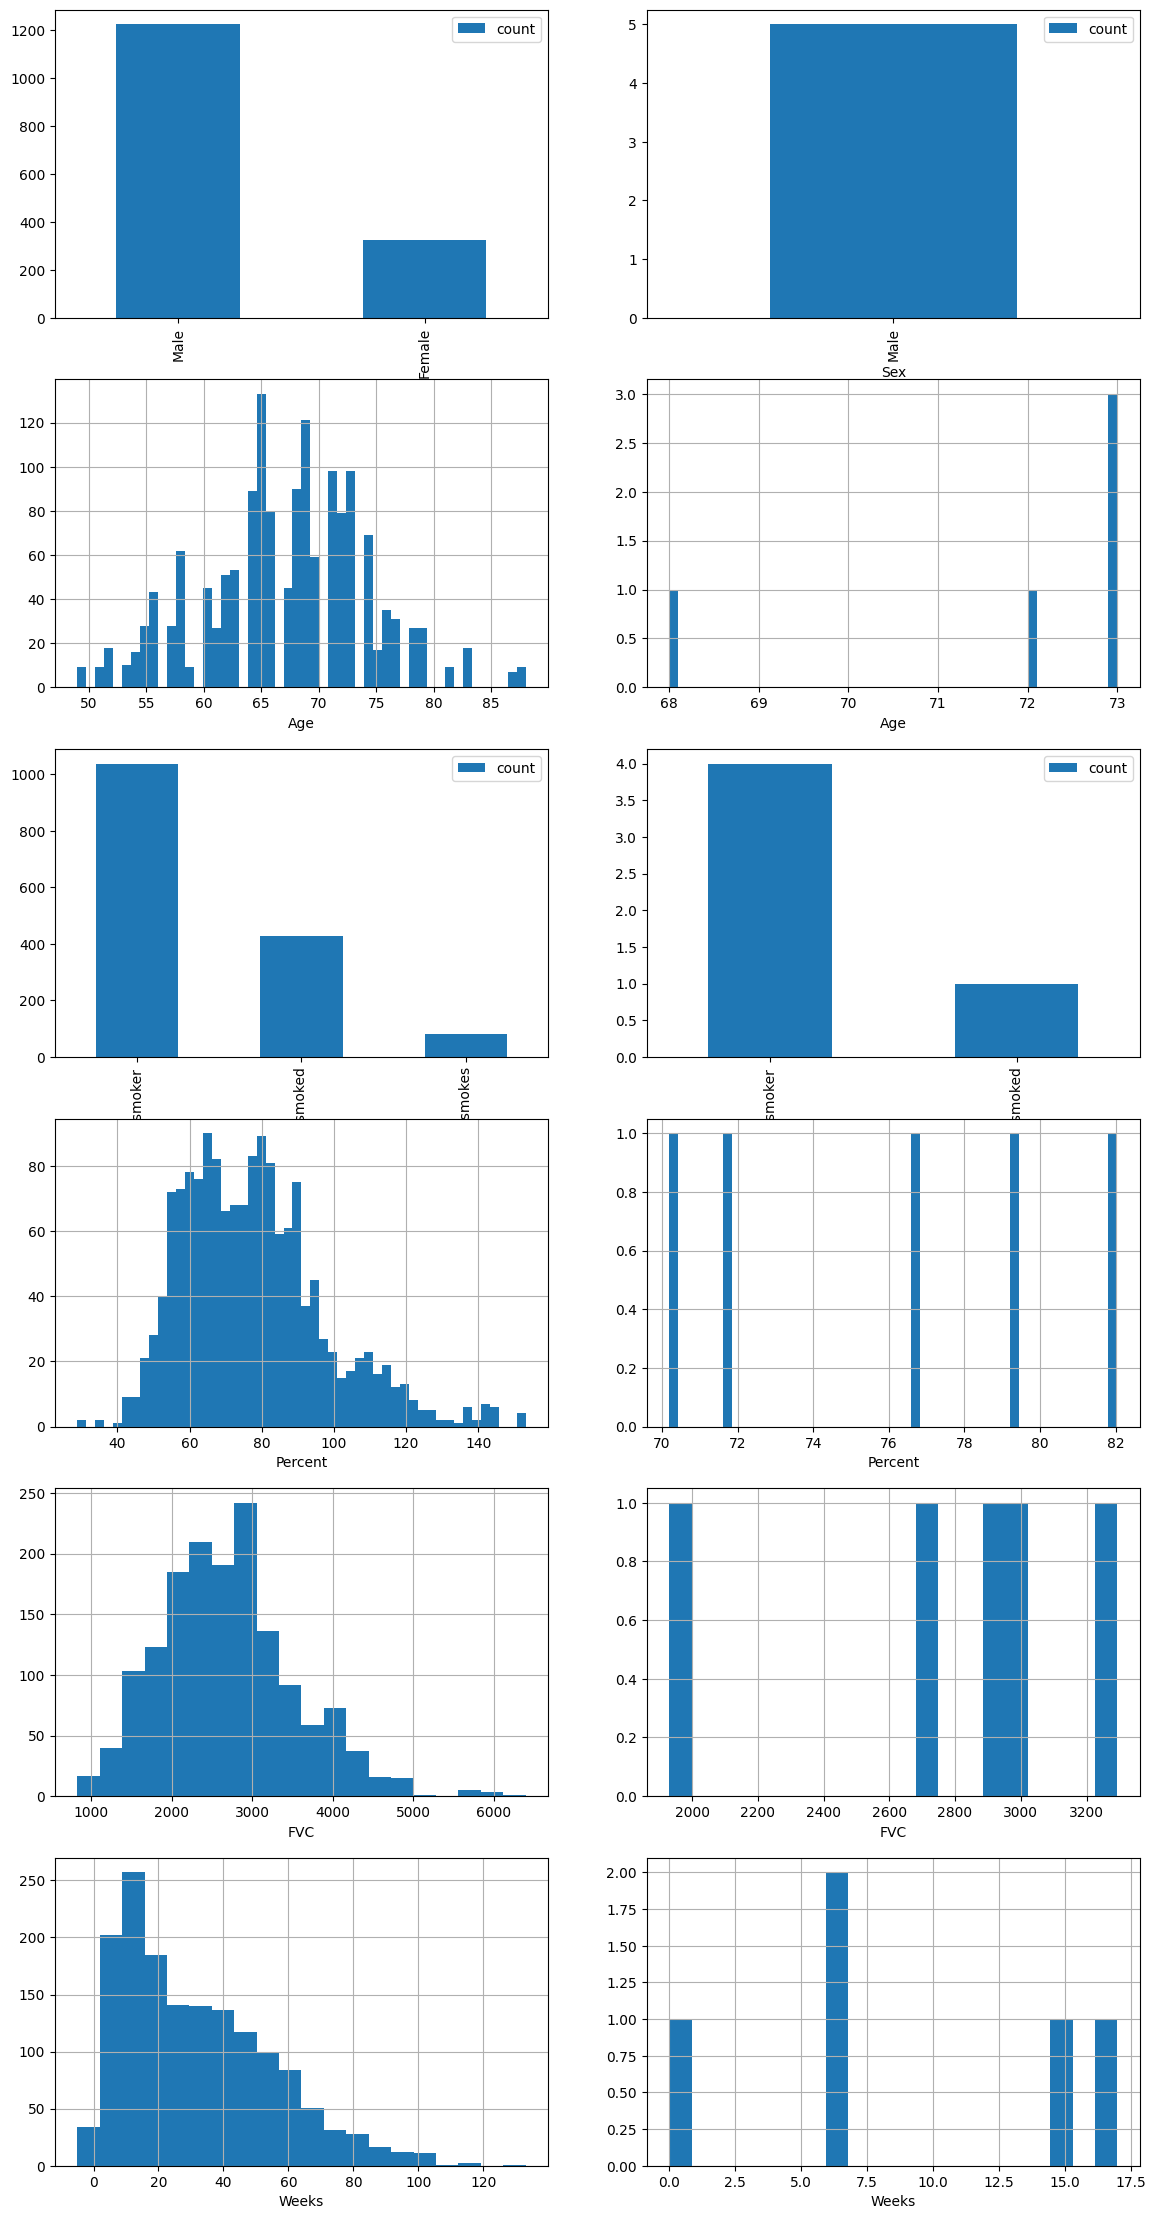

In [ ]:
fig, axs = plt.subplots(6,2, figsize=(14,28))

train['Sex'].value_counts().plot(kind='bar', legend=True, ax=axs[0,0])
test['Sex'].value_counts().plot(kind='bar', legend=True, ax=axs[0,1])

train['Age'].hist(bins=50, ax=axs[1,0])
test['Age'].hist(bins=50, ax=axs[1,1])
axs[1,0].set_xlabel('Age')
axs[1,1].set_xlabel('Age')

train['SmokingStatus'].value_counts().plot(kind='bar', legend=True, ax=axs[2,0])
test['SmokingStatus'].value_counts().plot(kind='bar', legend=True, ax=axs[2,1])

train['Percent'].hist(bins=50, ax=axs[3,0])
test['Percent'].hist(bins=50, ax=axs[3,1])
axs[3,0].set_xlabel('Percent')
axs[3,1].set_xlabel('Percent')

train['FVC'].hist(bins=20, ax=axs[4,0])
test['FVC'].hist(bins=20, ax=axs[4,1])
axs[4,0].set_xlabel('FVC')
axs[4,1].set_xlabel('FVC')

train['Weeks'].hist(bins=20, ax=axs[5,0])
test['Weeks'].hist(bins=20, ax=axs[5,1])
axs[5,0].set_xlabel('Weeks')
axs[5,1].set_xlabel('Weeks')

plt.show()

In [ ]:
len(lstFilesDCM)

34287